# Drift shadow — pre-merge test notebook (branch `drift-shadow`)

**What the drift shadow is.** R replicate *populations* of shadow individuals, each with a full
genome (LUT, egenes, active mask, neutral marker). Every step each replicate receives exactly the
real run's death and birth counts (uniform victims; uniform parents, with replacement, among the
survivors), and each shadow birth replays one real birth's *realized* mutation counts
`(nf, na, ne, nm)` through the same operator (`genome_mutate`). Nothing selects. Real and shadow
are projected into the fixed spaces (eg: 729 ternary keys; dyn: per-input allele frequency
weighted by the real query counts; marker: 729 keys) and scored with exchangeable rank statistics
(`python/drift_stats.py`). Design: `Docs/shadows.md` §5–6; implementation notes: its
"Implementation" section.

Sections: 1 parity / observer · 2 C vs Python reference · 3 validation (a) synthetic neutral ·
4 validation (b) power · 5 validation (c) EvoCA · 6 timing. Heavy campaigns were run by
`tools/drift_validation.py` and are loaded from `drift-shadow-validation.json`; quick live checks
run here.

In [1]:
import os, sys, json, hashlib, time
import numpy as np
import matplotlib.pyplot as plt
root = os.getcwd()
while not os.path.exists(os.path.join(root, 'C', 'evoca.h')):
    root = os.path.dirname(root)
sys.path.insert(0, os.path.join(root, 'python'))
from evoca_explore import run_sim, build_sim
from drift_stats import drift_statistics, consistency_stats
V = json.load(open(os.path.join(root, 'tests', 'notebooks', 'drift-shadow-validation.json')))
BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
print('repo root:', root)

repo root: /Users/n/Projects/EvoCA/.claude/worktrees/agent-ab496f36a0a78986e


## 1. Parity and the observer property
Stored `tools/parity_probe.py` result vs a build of `main` 3598e08 (food_cap 0), then a live check: same seed, drift off / drift R=8 / drift + marker → identical real lattices.

In [2]:
print(json.dumps(V['parity'], indent=1))
P = dict(food_inc=0.018, m_scale=2.5, gdiff=0.08, mu_lut=0.01, mu_egene=0.003,
         mu_egenome=0.003, p_dup_egene=1.0, tax=0.035, tax_per_egene=0.0008)
def traj(R=0, mk=0.0):
    s = build_sim(P, N=64, seed=7); s.set_marker_mu(mk)
    if R: s.fs_drift_enable(R)
    out = []
    for t in range(400):
        s.step()
        if t % 100 == 99:
            out.append(hashlib.sha1(s.get_v().tobytes() + s.get_alive().tobytes()
                                    + s.get_lut_hashes().tobytes()).hexdigest()[:12])
    s.free(); return out
a, b, c = traj(), traj(8), traj(8, 0.05)
print(a); print('identical:', a == b == c)

{
 "baseline": "main 3598e08 (detached worktree build)",
 "command": "tools/parity_probe.py run <root> <out> 0  (food_cap=0); cmp",
 "refactor_commit_b2752ca": {
  "traj": "IDENTICAL",
  "BAD": 0,
  "common_keys": 84
 },
 "branch_default_fs_shadow_both": {
  "traj": "IDENTICAL",
  "BAD": 0,
  "common_keys": 84,
  "new_keys": "drift_* / *_concentration_* / fs_* / marker_mu"
 },
 "extra": "restricted_mu=1 and p_dup<1 trajectories hash-identical over 800 steps (refactor)"
}
['394d16570453', '448c20ab4c61', '79818469c58d', '30e0c47b2034']
identical: True


## 2. C replicates vs the pure-Python reference (bit parity)
`python/drift_ref.py` ports the replicate step draw for draw. 300 random event-stream steps here (the test runs 1000).

In [3]:
import ctypes
from drift_ref import Replicate, drift_seed_for
from evoca_py import EvoCA
lib = EvoCA()._lib
rng = np.random.default_rng(3); n0, R, seed = 40, 3, 99
lut = rng.integers(0, 256, (n0, 32), dtype=np.uint8); lut[:, 31] &= 3
eg = rng.integers(0, 64, (n0, 8), dtype=np.uint8); egm = rng.integers(0, 64, (n0, 8), dtype=np.uint8)
act = rng.integers(1, 256, n0, dtype=np.uint8); mk = rng.integers(0, 64, n0).astype(np.uint16)
U8, CI, I32 = ctypes.POINTER(ctypes.c_uint8), ctypes.POINTER(ctypes.c_int), ctypes.POINTER(ctypes.c_int32)
lib.evoca_fs_drift_synth_init(R, 300, n0, lut.ctypes.data_as(U8), eg.ctypes.data_as(U8), egm.ctypes.data_as(U8),
                              act.ctypes.data_as(U8), mk.ctypes.data_as(ctypes.POINTER(ctypes.c_uint16)), seed)
refs = [Replicate(lut, eg, egm, act, mk, drift_seed_for(seed, r)) for r in range(R)]
c = np.zeros((R, 250), np.int32); e = np.zeros((R, 729), np.int32); m = np.zeros((R, 729), np.int32)
n = np.zeros(R, np.int32); T = np.zeros(R, np.int64); nq = np.ones(250); bad = 0
for t in range(300):
    D = int(rng.integers(0, 4)); B = D + int(rng.integers(0, 2)) if n.min() < 60 else D
    recs = np.ascontiguousarray(np.stack([rng.poisson(1.5, B), rng.poisson(.4, B), rng.poisson(.8, B),
                                          rng.poisson(.5, B)], 1).astype(np.int32))
    lib.evoca_fs_drift_synth_run(1, np.array([D], np.int32).ctypes.data_as(CI), np.array([B], np.int32).ctypes.data_as(CI),
                                 recs.ctypes.data_as(CI), nq.ctypes.data_as(ctypes.POINTER(ctypes.c_double)), 0)
    for ref in refs: ref.step(D, [tuple(map(int, r)) for r in recs])
    lib.evoca_fs_drift_tallies(c.ctypes.data_as(I32), e.ctypes.data_as(I32), m.ctypes.data_as(I32),
                               n.ctypes.data_as(I32), T.ctypes.data_as(ctypes.POINTER(ctypes.c_int64)))
    bad += sum(not (np.array_equal(c[r], f.c) and np.array_equal(e[r], f.e) and np.array_equal(m[r], f.m))
               for r, f in enumerate(refs))
lib.evoca_fs_drift_disable()
print('mismatching replicate-steps:', bad, '| final sizes', n)

mismatching replicate-steps: 0 | final sizes [60 60 60]


## 3. Validation (a): synthetic neutral (exact null)
Np=500, 25 births/deaths per step, 1,500 steps (75 generations), 400 runs per cell, R=19
(rank p at R=8 cannot reach 0.05). Acceptance (doc §7a): rejection at α=0.05 in [0.028, 0.072]
per cell; p-value uniformity (χ² on the 20 discrete values, p>0.01); mean z within ±0.10;
sd z in [0.90, 1.20]; per-bucket |z|>3 ≤ 1 % of present components.

cell                     dyn_consistency      eg_concentration     dyn_concentration                dyn_tv                 eg_tv  marker_concentration   |z|>3 frac dyn/eg
th=0.5    uniform   0.058 z+0.00/1.09  0.062 z-0.06/1.17  0.043 z+0.02/1.04  0.025 z-0.08/0.99  0.058 z+0.14/1.25  0.075 z+0.04/1.18   0.0463/0.0516
th=0.5    geo0.7    0.085 z+0.01/1.16  0.040 z-0.06/1.10  0.087 z-0.04/1.24  0.045 z+0.05/1.25  0.048 z+0.08/1.20  0.065 z-0.05/1.18   0.0046/0.0502
th=0.5    geo0.9    0.045 z+0.08/1.03  0.070 z+0.06/1.08  0.040 z+0.03/1.16  0.045 z-0.05/1.09  0.035 z+0.01/1.17  0.050 z-0.05/1.20   0.0133/0.0490
th=2.0    uniform   0.045 z-0.06/1.10  0.045 z-0.02/1.03  0.048 z-0.06/1.12  0.070 z+0.12/1.16  0.052 z-0.02/1.15  0.068 z+0.02/1.16   0.0312/0.0514
th=2.0    geo0.7    0.052 z+0.08/1.10  0.045 z+0.04/1.07  0.058 z+0.07/1.09  0.052 z+0.02/1.23  0.052 z+0.04/1.13  0.048 z+0.03/1.02   0.0034/0.0496
th=2.0    geo0.9    0.055 z-0.05/1.17  0.045 z-0.03/1.04  0.062 z-0.06/1.21  0.072 z

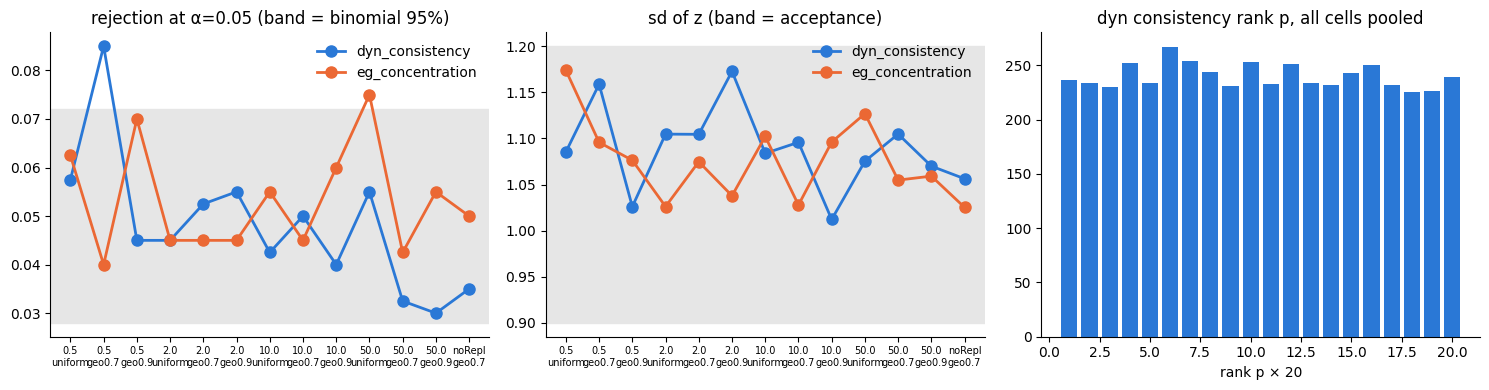

In [4]:
A = V['a']
rows = A['cells'] + [dict(A['variant'], theta='noRepl', access='geo0.7')]
stats = ['dyn_consistency', 'eg_concentration', 'dyn_concentration', 'dyn_tv', 'eg_tv', 'marker_concentration']
print(f"{'cell':18s}" + ''.join(f'{s:>22s}' for s in stats) + '   |z|>3 frac dyn/eg')
for c in rows:
    x = c['R19']
    print(f"th={c['theta']!s:6s} {c['access']:8s}" + ''.join(
        f"  {x[s]['reject_005']:.3f} z{x[s]['z_mean']:+.2f}/{x[s]['z_sd']:.2f}" for s in stats)
        + f"   {x['dyn_frac_z3']:.4f}/{x['eg_frac_z3']:.4f}")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
lab = [f"{c['theta']}\n{c['access']}" for c in rows]
for s, col in (('dyn_consistency', BLUE), ('eg_concentration', ORANGE)):
    ax[0].plot(range(len(rows)), [c['R19'][s]['reject_005'] for c in rows], 'o-', color=col, lw=2, ms=8, label=s)
    ax[1].plot(range(len(rows)), [c['R19'][s]['z_sd'] for c in rows], 'o-', color=col, lw=2, ms=8, label=s)
ax[0].axhspan(0.028, 0.072, color='0.9'); ax[0].set_title('rejection at α=0.05 (band = binomial 95%)')
ax[1].axhspan(0.90, 1.20, color='0.9'); ax[1].set_title('sd of z (band = acceptance)')
for a_ in ax[:2]:
    a_.set_xticks(range(len(rows))); a_.set_xticklabels(lab, fontsize=7); a_.legend(frameon=False)
h = np.sum([c['R19']['dyn_consistency']['p_hist'] for c in A['cells']], axis=0)
ax[2].bar(range(1, 21), h, color=BLUE); ax[2].set_title('dyn consistency rank p, all cells pooled')
ax[2].set_xlabel('rank p × 20')
for a_ in ax: a_.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

**Reading.** The primary statistics are calibrated: rank p-values uniform (χ² p>0.01 in every
primary cell), z mean within ±0.08, sd 1.01–1.17. Two of 26 primary cell-checks sit just outside
the per-cell 95% band (dyn consistency θ=0.5 geo0.7: 0.085; eg concentration θ=50 uniform: 0.075);
about 1.3 are expected by chance across 26. The demographic variant (real parents without
replacement) passes. **The per-bucket |z|>3 ≤ 1 % criterion fails for eg and marker
(1.8–5.2 %) and for dyn in low-θ uniform cells (up to 4.6 %)**: per-component cumulative activity is
heavy-tailed (lineage clumps) and normal-theory z with R=19 references cannot be calibrated per
bucket. The tracking shadow gave 23–35 % on its stylized model. `*_drift_nhi`, which subtracts the
replicates' own count, is the calibrated tail statistic. At R=8 the z sd is 1.2–1.4, matching the
t₇ expectation (≈1.25).

## 4. Validation (b): power (Np=500, θ=10, R=19, α=0.05; R=8 at its floor α=1/9)
Acceptance: ≥0.70 for s=0.05 on the top input (30 % of query mass) and ≥0.65 for s=0.02 on 5 top
inputs at 150 generations; monotone in s and generations.

cell                               cons  dconc    dTV    egC | R8: cons dconc dTV
purify s=0.05 k=1 gen150           0.69   0.85   0.36   0.06 | 0.70 0.92 0.51
purify s=0.02 k=5 gen150           0.79   0.66   0.45   0.03 | 0.89 0.80 0.56
purify s=0.01 k=1 gen75            0.11   0.16   0.08   0.08 | 0.23 0.23 0.16
purify s=0.02 k=1 gen75            0.17   0.20   0.10   0.07 | 0.26 0.29 0.20
purify s=0.05 k=1 gen75            0.34   0.39   0.14   0.01 | 0.47 0.51 0.23
purify s=0.01 k=1 gen150           0.14   0.16   0.06   0.04 | 0.27 0.30 0.15
purify s=0.02 k=1 gen150           0.24   0.25   0.12   0.06 | 0.36 0.40 0.13
directional s=0.05 k=1 gen150      0.01   0.01   0.85   0.07 | 0.05 0.04 0.87
directional s=0.02 k=5 gen150      0.00   0.00   0.67   0.04 | 0.00 0.00 0.71
eg family s=0.05 gen150            0.07   0.06   0.02   0.09 | 0.16 0.16 0.08


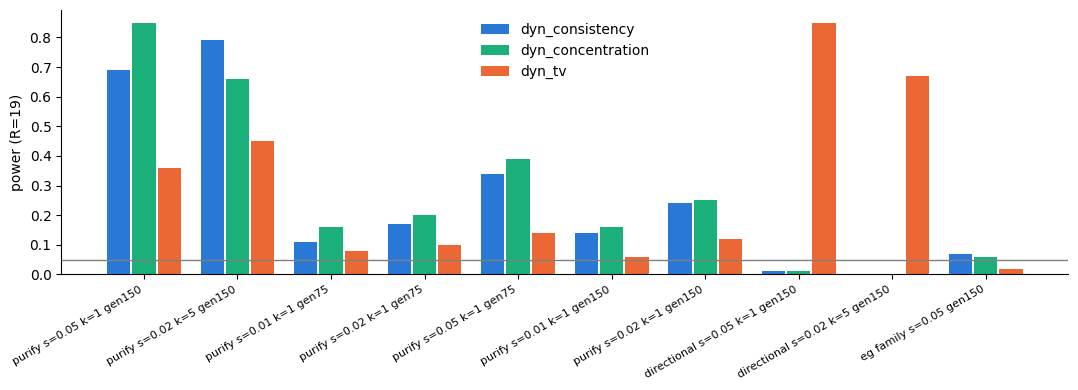

In [5]:
B_ = V['b']['cells']
print(f"{'cell':32s} {'cons':>6s} {'dconc':>6s} {'dTV':>6s} {'egC':>6s} | R8: cons dconc dTV")
for c in B_:
    x, y = c['R19'], c['R8']
    print(f"{c['name']:32s} {x['power_dyn_consistency']:6.2f} {x['power_dyn_concentration']:6.2f} "
          f"{x['power_dyn_tv']:6.2f} {x['power_eg_concentration']:6.2f} | {y['power_dyn_consistency']:.2f} "
          f"{y['power_dyn_concentration']:.2f} {y['power_dyn_tv']:.2f}")
fig, ax = plt.subplots(figsize=(11, 4))
xs = np.arange(len(B_)); w = 0.27
for k, (s, col) in enumerate((('power_dyn_consistency', BLUE), ('power_dyn_concentration', AQUA), ('power_dyn_tv', ORANGE))):
    ax.bar(xs + (k - 1) * w, [c['R19'][s] for c in B_], w * 0.92, color=col, label=s.replace('power_', ''))
ax.set_xticks(xs); ax.set_xticklabels([c['name'] for c in B_], rotation=30, ha='right', fontsize=8)
ax.axhline(0.05, color='0.5', lw=1); ax.legend(frameon=False); ax.set_ylabel('power (R=19)')
ax.spines[['top', 'right']].set_visible(False); plt.tight_layout(); plt.show()

**Reading.** Power criteria pass: 0.85 (dyn concentration; consistency 0.69) for s=0.05 k=1 and
0.79 (consistency) for s=0.02 k=5; monotone in s and in generations. **Directional selection
(a sweep of a new allele) is invisible to the one-sided statistics** (power 0.00–0.01, mean Z
negative): the sweep splits cumulative activity between the old and the new output, which lowers
cumulative homozygosity. The two-sided `*_drift_tv` test added on this branch detects it (0.85,
0.67). eg family selection on the founder's own digit has low power (0.09).

## 5. Validation (c): EvoCA runs
All with R=19, 5,000 steps unless noted; marker_mu=0.003 in evolving runs.

In [6]:
Cc = V['c']
print('frozen-clonal marker null (20 seeds per cell):')
for k, v in Cc['marker_null'].items():
    print(f"  {k:14s} reject one-sided {v['reject_conc_005']:.2f}  reject TV {v['reject_tv_005']:.2f}  "
          f"marker z {v['z_mean']:+.1f} ± {v['z_sd']:.1f}  |conc| q95 {v['abs_conc_q95']:.2f}  TV q95 {v['tv_q95']:.2f}")
print('standing-variation freeze:', Cc['standing_variation'])
print('lineage mutation load (marker weight) real vs shadow:')
for r in V['lineage_depth']['rows']:
    print(f"  N={r['N']} seed={r['seed']}: real {r['real']:.3f}  shadow {r['shadow_mean']:.3f} ± {r['shadow_sd']:.3f}")
labs = ['draft_JOINT', 'draft_LUT_only', 'recipe_joint_winner', 'recipe_frozen_control']
print(f"\n{'run':24s} {'egConc':>7s} {'mkConc':>7s} {'eg-mk':>7s} {'dynZcons':>9s} {'dynTVz':>7s} {'negene':>7s} {'exprBias':>8s}")
for lab in labs:
    for r in [r for r in Cc['rows'] if r['label'] == lab]:
        print(f"{lab:24s} {r['eg_drift_concentration']:7.2f} {r['marker_drift_concentration']:7.2f} "
              f"{r['eg_drift_concentration'] - r['marker_drift_concentration']:7.2f} {r['dyn_drift_consistency']:9.1f} "
              f"{r['dyn_drift_tv_z']:7.1f} {r['negene_drift']:7.2f} {r['dyn_expression_bias']:8.3f}")

frozen-clonal marker null (20 seeds per cell):
  N64_mu0.001    reject one-sided 0.00  reject TV 0.75  marker z -3.9 ± 2.0  |conc| q95 0.30  TV q95 0.15
  N64_mu0.003    reject one-sided 0.00  reject TV 0.95  marker z -5.4 ± 1.8  |conc| q95 0.67  TV q95 0.25
  N64_mu0.01     reject one-sided 0.00  reject TV 0.95  marker z -7.1 ± 2.6  |conc| q95 1.30  TV q95 0.35
  N128_mu0.001   reject one-sided 0.00  reject TV 1.00  marker z -8.5 ± 3.8  |conc| q95 0.32  TV q95 0.14
  N128_mu0.003   reject one-sided 0.00  reject TV 1.00  marker z -12.4 ± 3.1  |conc| q95 0.67  TV q95 0.23
  N128_mu0.01    reject one-sided 0.00  reject TV 1.00  marker z -18.1 ± 4.0  |conc| q95 1.38  TV q95 0.32
standing-variation freeze: {'n': 20, 'n_dyn_z_pos': 20, 'n_dyn_consistency_pos': 20, 'n_dyn_tv_p_floor': 17}
lineage mutation load (marker weight) real vs shadow:
  N=64 seed=1: real 0.269  shadow 0.157 ± 0.055
  N=64 seed=2: real 0.136  shadow 0.119 ± 0.035
  N=128 seed=1: real 0.280  shadow 0.129 ± 0.013
  N=128

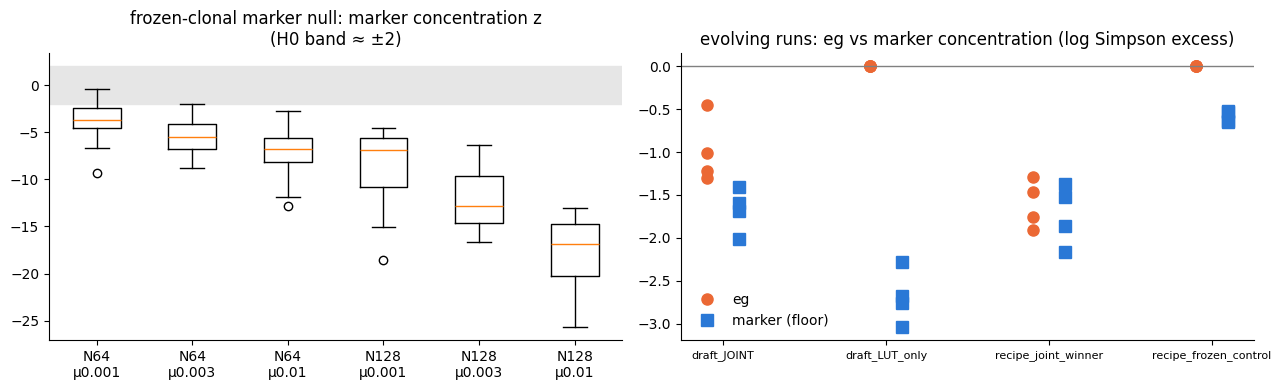

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
fz = [r for r in Cc['rows'] if r['label'] == 'frozen_clonal_marker']
groups = sorted({(r['N'], r['marker_mu']) for r in fz})
ax[0].boxplot([[r['marker_drift_z'] for r in fz if (r['N'], r['marker_mu']) == g] for g in groups],
              tick_labels=[f'N{g[0]}\nμ{g[1]}' for g in groups])
ax[0].axhspan(-2, 2, color='0.9'); ax[0].set_title('frozen-clonal marker null: marker concentration z\n(H0 band ≈ ±2)')
for i, lab in enumerate(labs):
    rr = [r for r in Cc['rows'] if r['label'] == lab]
    ax[1].plot([i - 0.1] * len(rr), [r['eg_drift_concentration'] for r in rr], 'o', color=ORANGE, ms=8,
               label='eg' if i == 0 else None)
    ax[1].plot([i + 0.1] * len(rr), [r['marker_drift_concentration'] for r in rr], 's', color=BLUE, ms=8,
               label='marker (floor)' if i == 0 else None)
ax[1].set_xticks(range(len(labs))); ax[1].set_xticklabels(labs, fontsize=8); ax[1].axhline(0, color='0.5', lw=1)
ax[1].set_title('evolving runs: eg vs marker concentration (log Simpson excess)'); ax[1].legend(frameon=False)
for a_ in ax: a_.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

**Reading (the EvoCA verdict).**

* **Clonal wiring / frozen control:** every eg and dyn drift statistic is exactly 0 (nothing varies).
* **Standing-variation freeze:** dyn_drift_z > 0 in 20/20 seeds (accept ≥ 18/20). Selection sorting
  standing variation reads positive, as designed.
* **Frozen-clonal marker null FAILS calibration.** The marker is read by nothing, yet the panmictic
  shadow misreads it: marker concentration z −3.9 to −18 (more negative at N=128), TV p at the
  floor in 75–100 % of seeds. Cause (measured): real lineages carry 1.1–2.2× more mutation events
  than the shadow's (marker weight above), i.e. EvoCA's age/state-structured life history gives
  newborn lineages higher reproductive value, so mutations accumulate faster along surviving
  lineages than uniform parent choice implies. The one-sided tests are therefore *conservative*
  (0 rejections) but strongly negatively biased; the two-sided TV test is not usable on EvoCA
  without the marker floor.
* **Evolving runs:** no seed shows one-sided eg or dyn drift excess (p = 1 throughout); eg
  concentration −0.45 to −1.9 and dyn consistency −12 to −43, in the direction of the
  lineage-depth bias. Against the marker floor in the same run, eg − marker is positive in 4/4 JOINT
  seeds (+0.38 to +1.56) and 2/4 winner seeds (−0.39 to +0.69): suggestive in JOINT, not
  established (marker and egene kernels are not identical). There is no dyn-space marker, so dyn
  cannot be referred to a floor. **negene_drift −0.46 to −0.86** (real Negene below neutral),
  *opposite* to the bias direction: the one robust selection reading (egene number, under
  tax_per_egene).
* Q9 check: run-mean weights change dyn consistency by ≤ 20 % (−12.2 → −14.7, 5.15 → 5.21): not
  material; contemporaneous weights kept.
* dyn_expression_bias: 0 in frozen clonal runs, 0.02–0.03 standing variation, 0.06–0.07 winner,
  0.11–0.13 JOINT / LUT_only.

## 6. Timing (N=256, steady state Np≈15.5k, JOINT base)
Acceptance: ≤ +60 % at R=8.

In [8]:
Tm = V['timing']
for k in ('off', 'drift_R1', 'drift_R8', 'drift_R16'):
    print(f"{k:10s} {Tm[k]['ms_per_step']:.3f} ms/step  ({Tm[k]['overhead_pct']:+.0f}%)")
print('note: the tracking shadow is always computed inside evoca_step, so off == tracking at the C level')
s = build_sim(P, N=128, seed=1)
for _ in range(800): s.step()
t = time.perf_counter(); [s.step() for _ in range(300)]; off = (time.perf_counter() - t) / 300 * 1e3
s.fs_drift_enable(8); t = time.perf_counter(); [s.step() for _ in range(300)]; on = (time.perf_counter() - t) / 300 * 1e3
s.free(); print(f'live N=128: off {off:.3f} ms, drift R=8 {on:.3f} ms ({100 * (on / off - 1):+.0f}%)')

off        1.633 ms/step  (+0%)
drift_R1   1.971 ms/step  (+21%)
drift_R8   2.166 ms/step  (+33%)
drift_R16  2.446 ms/step  (+50%)
note: the tracking shadow is always computed inside evoca_step, so off == tracking at the C level


live N=128: off 0.504 ms, drift R=8 0.666 ms (+32%)
